# 06 - Constant coefficients: the characteristic equation

**MATH 331 - Differential Equations.** Unit U5-U6, Sessions 11-12: homogeneous equations
$ay'' + by' + cy = 0$ with constant coefficients; distinct real, repeated and complex roots;
Euler's formula; higher-order equations. Prerequisite: notebook 05 (Wronskian, Abel's theorem).
Application: notebook 07 (mass-spring-damper).

**Sources used to compile this notebook** (full list in Section 9)
* [L] J. Lebl, *Notes on Diffy Qs* (`ode/FullText_Diff_Eq_For_Engineers.pdf`), **Section 2.2**
  (opening example $y'' - 6y' + 8y = 0$; Theorems 2.2.1-2.2.3; Examples 2.2.1-2.2.4; the
  repeated root as a limit of distinct roots; Euler's formula) and **Section 2.3**
  (Example 2.3.3, a third-order equation).
* [AD] W.A. Adkins, M.G. Davidson, *Ordinary Differential Equations* (Springer, 2012),
  **Sect. 3.3** (Example 7, Theorem 8 and Remark 9 (Abel), Exercises 1-22).
* [AWH] G.B. Arfken, H.J. Weber, F.E. Harris, *Mathematical Methods for Physicists*, 7th ed.,
  **Section 7.6** (Wronskian of $\sin\omega x, \cos\omega x$, Example 7.6.1).

**What you will learn**
1. Why the guess $y = e^{rx}$ turns a differential equation into an **algebraic** one.
2. A *derivation* (not just a guess) of the general solution in all three cases, by
   factoring the operator $aD^2 + bD + c = a(D - r_1)(D - r_2)$.
3. Where $x\,e^{rx}$ comes from when the root is repeated (two independent explanations).
4. How Euler's formula turns complex roots into real oscillations.
5. How the **position of the roots in the complex plane** determines the shape of every solution,
   and how this agrees with Abel's theorem.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (analytic solutions, Euler/Heun/RK4, slope fields, phase lines).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp                     # noqa: F401  (not used in every notebook)
from IPython.display import Math, display                 # noqa: F401  (not used in every notebook)
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 1. The key identity: $L[e^{rx}] = P(r)\,e^{rx}$

Write $D = \dfrac{d}{dx}$ and $L = aD^2 + bD + c$ ($a \neq 0$), so the equation is $L[y] = 0$. For the
exponential $e^{rx}$, each derivative only multiplies by $r$: $De^{rx} = re^{rx}$, $D^2e^{rx} = r^2e^{rx}$.
Hence

$$
\boxed{\;L[e^{rx}] = (ar^2 + br + c)\,e^{rx} = P(r)\,e^{rx}\;}
$$

$P(r) = ar^2 + br + c$ is the **characteristic polynomial**. Since $e^{rx} \neq 0$:
$\;e^{rx}$ solves $L[y] = 0$ **if and only if** $P(r) = 0$, the **characteristic equation**
[L, Section 2.2]. The calculus problem has become a high-school algebra problem. Its roots are

$$
r_{1,2} = \frac{-b \pm \sqrt{b^2 - 4ac}}{2a}.
$$

(Why try $e^{rx}$? Because for $y' = ky$ the answer was $e^{kx}$ (notebook 01), and exponentials are
the functions whose derivatives are proportional to themselves. Lebl's footnote calls such an educated guess
an *ansatz*.)

**The opening example of [L, Section 2.2].** $\;y'' - 6y' + 8y = 0$, $\;P(r) = r^2 - 6r + 8 = (r-2)(r-4)$.

In [2]:
x, r = sp.symbols("x r")
y = sp.Function("y")

# L[e^{rx}] / e^{rx} = P(r): SymPy confirms the key identity
a_, b_, c_ = sp.symbols("a b c")
L = lambda f: a_ * sp.diff(f, x, 2) + b_ * sp.diff(f, x) + c_ * f      # noqa: E731
print("L[e^{rx}] / e^{rx} =", sp.simplify(L(sp.exp(r * x)) / sp.exp(r * x)))

# The opening example: roots of r^2 - 6r + 8, then the IVP y(0) = -2, y'(0) = 6
print("roots:", sp.solve(r**2 - 6 * r + 8, r), "   odelib:", ol.characteristic_roots(1, -6, 8))
ode = sp.Eq(y(x).diff(x, 2) - 6 * y(x).diff(x) + 8 * y(x), 0)
sol = sp.dsolve(ode, y(x), ics={y(0): -2, y(x).diff(x).subs(x, 0): 6})
display(sol)                                   # Lebl: y = -7 e^{2x} + 5 e^{4x}
print("checkodesol:", sp.checkodesol(ode, sol))

L[e^{rx}] / e^{rx} = a*r**2 + b*r + c
roots: [2, 4]    odelib: ((4+0j), (2+0j))


Eq(y(x), (5*exp(2*x) - 7)*exp(2*x))

checkodesol: (True, 0)


## 2. A derivation: factoring the operator

Guessing $e^{rx}$ produces solutions, but does it produce **all** of them? Here is an argument
that does not rely on guessing. Because the coefficients are constant, the operator factors exactly
like the polynomial:

$$
aD^2 + bD + c = a\,(D - r_1)(D - r_2) \qquad\text{(expand: } a[D^2 - (r_1+r_2)D + r_1r_2]\text{, and use } r_1 + r_2 = -\tfrac ba,\ r_1r_2 = \tfrac ca\text{)}.
$$

The building block is the identity

$$
(D - r)\big[e^{rx}u\big] = re^{rx}u + e^{rx}u' - re^{rx}u = e^{rx}\,u' ,
$$

i.e. $(D - r)y = e^{rx}\,(e^{-rx}y)'$. Now solve $L[y] = 0$ in **two first-order steps**: set
$z = (D - r_2)y$, so that $(D - r_1)z = 0$.

1. $(D - r_1)z = 0 \;\Rightarrow\; (e^{-r_1x}z)' = 0 \;\Rightarrow\; z = A\,e^{r_1x}$.
2. $(D - r_2)y = Ae^{r_1x} \;\Rightarrow\; (e^{-r_2x}y)' = A\,e^{(r_1 - r_2)x}$. Integrate:
   * **if $r_1 \neq r_2$**: $\;e^{-r_2x}y = \dfrac{A}{r_1 - r_2}e^{(r_1-r_2)x} + B$, so
     $\;\boxed{y = C_1e^{r_1x} + C_2e^{r_2x}}$;
   * **if $r_1 = r_2 = r$**: $\;e^{-rx}y = Ax + B$, so $\;\boxed{y = (C_1 + C_2x)\,e^{rx}}$.

Every step was an equivalence, so **every** solution has this form: this proves
[L, Theorem 2.2.1] directly. The term $x\,e^{rx}$ is not magic: it comes from integrating a constant.
The argument works verbatim for complex $r_1, r_2$ (Section 5).

In [3]:
# Check the building block (D - r)[e^{rx} u] = e^{rx} u' for an arbitrary function u
u = sp.Function("u")
lhs = sp.diff(sp.exp(r * x) * u(x), x) - r * sp.exp(r * x) * u(x)
print("(D - r)[e^{rx} u] - e^{rx} u' =", sp.simplify(lhs - sp.exp(r * x) * u(x).diff(x)))

# Check the factorisation a(D - r1)(D - r2) y = a y'' - a(r1 + r2) y' + a r1 r2 y on a generic y
r1, r2 = sp.symbols("r1 r2")
Dm = lambda rk, f: sp.diff(f, x) - rk * f                                 # noqa: E731  (D - rk) f
print("a(D-r1)(D-r2)y =", sp.expand(a_ * Dm(r1, Dm(r2, y(x)))))

(D - r)[e^{rx} u] - e^{rx} u' = 0
a(D-r1)(D-r2)y = a*r1*r2*y(x) - a*r1*Derivative(y(x), x) - a*r2*Derivative(y(x), x) + a*Derivative(y(x), (x, 2))


## 3. Case 1: two distinct real roots ($b^2 - 4ac > 0$)

$$
y = C_1e^{r_1x} + C_2e^{r_2x}, \qquad W[e^{r_1x}, e^{r_2x}] = (r_2 - r_1)\,e^{(r_1+r_2)x} \neq 0 .
$$

The Wronskian (notebook 05, Section 3.3) is never zero, so the two exponentials are a basis.
**[L, Example 2.2.1]:** $y'' - k^2y = 0$ gives $r = \pm k$ and $y = C_1e^{kx} + C_2e^{-kx}$, or
equivalently $y = D_1\cosh kx + D_2\sinh kx$, a basis better suited to initial conditions at $x = 0$
($\cosh 0 = 1$, $\sinh 0 = 0$).

The figure shows the opening example $-7e^{2x} + 5e^{4x}$ and its two "modes". With two real roots
a solution can cross zero **at most once**. (Setting $C_1e^{r_1x} + C_2e^{r_2x} = 0$ gives
$e^{(r_1 - r_2)x} = -C_2/C_1$, which has at most one solution.)

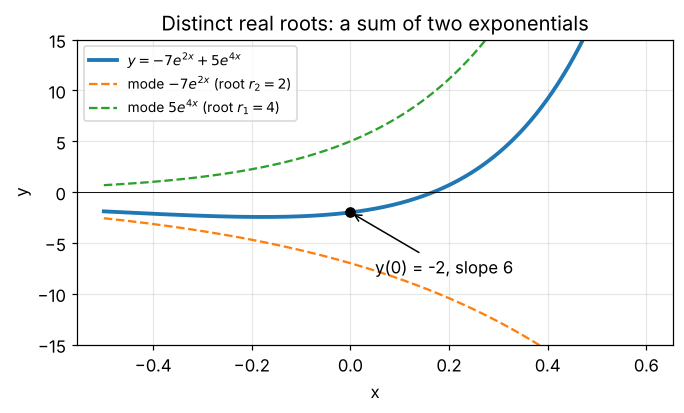

In [4]:
xs = np.linspace(-0.5, 0.6, 400)
y_exact = ol.constant_coefficient_solution(xs, 1, -6, 8, -2, 6)     # tested helper (see tests/)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(xs, y_exact, lw=2.5, label=r"$y = -7e^{2x} + 5e^{4x}$")
ax.plot(xs, -7 * np.exp(2 * xs), "--", label=r"mode $-7e^{2x}$ (root $r_2 = 2$)")
ax.plot(xs, 5 * np.exp(4 * xs), "--", label=r"mode $5e^{4x}$ (root $r_1 = 4$)")
ax.plot(0, -2, "ko")
ax.annotate("y(0) = -2, slope 6", (0, -2), (0.05, -8), arrowprops=dict(arrowstyle="->"))
ax.axhline(0, color="k", lw=0.6)
ax.set(xlabel="x", ylabel="y", ylim=(-15, 15), title="Distinct real roots: a sum of two exponentials")
ax.legend()
plt.show()

## 4. Case 2: a repeated root ($b^2 - 4ac = 0$)

Now $r_1 = r_2 = r = -b/(2a)$ and Section 2 gave $y = (C_1 + C_2x)e^{rx}$ [L, Theorem 2.2.1].
**[L, Example 2.2.2]:** $y'' - 8y' + 16y = 0$, $P(r) = (r - 4)^2$, $y = C_1e^{4x} + C_2xe^{4x}$.
**[AD, Sect. 3.3, Example 7]:** $y'' + 2y' + y = 0$, $y(0) = 2$, $y'(0) = -3$ gives
$y = 2e^{-t} - te^{-t}$.

A second explanation, from [L, Section 2.2]: **the repeated root is a limit of distinct roots.** When
$r_1 \neq r_2$, the combination

$$
\frac{e^{r_2x} - e^{r_1x}}{r_2 - r_1}
$$

is a solution (superposition). As $r_2 \to r_1 = r$ it is a difference quotient in the variable $r$,
so it converges to $\dfrac{\partial}{\partial r}e^{rx} = x\,e^{rx}$. Move the slider to bring the two roots together.

The Wronskian is $W[e^{rx}, xe^{rx}] = e^{2rx}$, never zero. A third way to get $xe^{rx}$ is
**reduction of order** (notebook 05, Section 6.2).

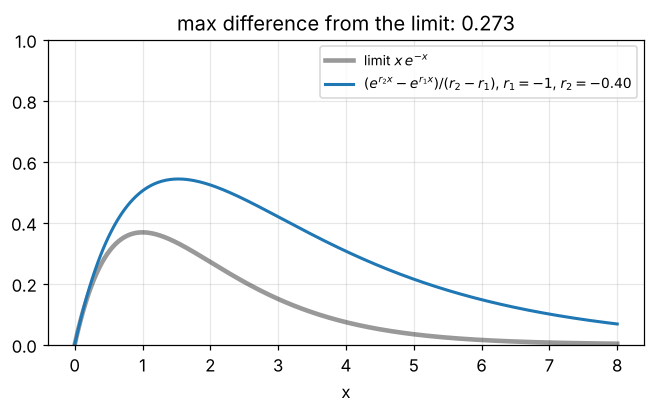

In [5]:
def plot_merging_roots(gap=1.0):
    """Solution (e^{r2 x} - e^{r1 x}) / (r2 - r1) with r1 = -1, r2 = -1 + gap, versus the limit x e^{-x}."""
    xs = np.linspace(0, 8, 400)
    rr1, rr2 = -1.0, -1.0 + gap
    quotient = (np.exp(rr2 * xs) - np.exp(rr1 * xs)) / (rr2 - rr1)
    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.plot(xs, xs * np.exp(-xs), "k", lw=3, alpha=0.4, label=r"limit $x\,e^{-x}$")
    ax.plot(xs, quotient, lw=2, label=fr"$(e^{{r_2x}}-e^{{r_1x}})/(r_2-r_1)$, $r_1=-1$, $r_2={rr2:.2f}$")
    diff = np.max(np.abs(quotient - xs * np.exp(-xs)))
    ax.set(xlabel="x", ylim=(0, 1.0), title=f"max difference from the limit: {diff:.3f}")
    ax.legend()
    plt.show()


plot_merging_roots(0.6)

In [6]:
interact(plot_merging_roots, gap=FloatSlider(value=0.6, min=0.01, max=0.9, step=0.01,
                                             description="r2 - r1", continuous_update=False))

# SymPy computes the limit symbolically
rr, h = sp.symbols("r h")
print("limit:", sp.limit((sp.exp((rr + h) * x) - sp.exp(rr * x)) / h, h, 0))
print("W[e^{rx}, x e^{rx}] =", sp.simplify(sp.wronskian([sp.exp(rr * x), x * sp.exp(rr * x)], x)))

interactive(children=(FloatSlider(value=0.6, continuous_update=False, description='r2 - r1', max=0.9, min=0.01…

limit: x*exp(r*x)
W[e^{rx}, x e^{rx}] = exp(2*r*x)


## 5. Case 3: complex roots ($b^2 - 4ac < 0$)

The roots are a conjugate pair $r = \alpha \pm i\beta$ with $\alpha = -\dfrac{b}{2a}$,
$\beta = \dfrac{\sqrt{4ac - b^2}}{2a}$. Section 2 still holds with complex numbers, giving the complex
solutions $e^{(\alpha \pm i\beta)x}$. To get **real** solutions we use **Euler's formula**
[L, Theorem 2.2.2]

$$
e^{i\theta} = \cos\theta + i\sin\theta \qquad\Longrightarrow\qquad e^{(\alpha \pm i\beta)x} = e^{\alpha x}\big(\cos\beta x \pm i\sin\beta x\big),
$$

and superposition: half the sum and $\frac{1}{2i}$ times the difference are real solutions:

$$
\boxed{\;y = e^{\alpha x}\big(C_1\cos\beta x + C_2\sin\beta x\big)\;} \qquad\text{[L, Theorem 2.2.3]},
\qquad W[e^{\alpha x}\cos\beta x,\, e^{\alpha x}\sin\beta x] = \beta\,e^{2\alpha x}.
$$

(Fact used: if a complex function solves an equation with **real** coefficients, so do its real and
imaginary parts, because $L[\operatorname{Re} y] = \operatorname{Re} L[y]$.)

**Reading the formula:** $\beta$ is the angular frequency of the oscillation (period $2\pi/\beta$),
$e^{\alpha x}$ is the envelope. **Amplitude-phase form:** $C_1\cos\beta x + C_2\sin\beta x = R\cos(\beta x - \delta)$
with $R = \sqrt{C_1^2 + C_2^2}$, $\tan\delta = C_2/C_1$ (notebook 07 uses it).

**[L, Example 2.2.3]:** $y'' + k^2y = 0$: $r = \pm ik$, $y = C_1\cos kx + C_2\sin kx$; Arfken's
Example 7.6.1 gives $W[\sin kx, \cos kx] = -k$.
**[L, Example 2.2.4]:** $y'' - 6y' + 13y = 0$, $y(0) = 0$, $y'(0) = 10$: $r = 3 \pm 2i$, $y = 5e^{3x}\sin 2x$.

In [7]:
# Euler's formula, checked symbolically and numerically
theta = sp.symbols("theta", real=True)
print("e^{i theta} =", sp.expand_complex(sp.exp(sp.I * theta)))
print("numerically: e^{i pi/3} =", np.exp(1j * np.pi / 3),
      " cos + i sin =", np.cos(np.pi / 3) + 1j * np.sin(np.pi / 3))

# Lebl Example 2.2.4 with dsolve, with odelib, and the Wronskian of the real basis
ode = sp.Eq(y(x).diff(x, 2) - 6 * y(x).diff(x) + 13 * y(x), 0)
display(sp.dsolve(ode, y(x), ics={y(0): 0, y(x).diff(x).subs(x, 0): 10}))
xs = np.linspace(0, 1.5, 7)
print("odelib vs 5 e^{3x} sin 2x, max difference:",
      np.max(np.abs(ol.constant_coefficient_solution(xs, 1, -6, 13, 0, 10)
                    - 5 * np.exp(3 * xs) * np.sin(2 * xs))))
al, be = sp.symbols("alpha beta", real=True)
print("W =", sp.simplify(sp.wronskian([sp.exp(al * x) * sp.cos(be * x), sp.exp(al * x) * sp.sin(be * x)], x)))

e^{i theta} = I*sin(theta) + cos(theta)
numerically: e^{i pi/3} = (0.5000000000000001+0.8660254037844386j)  cos + i sin = (0.5000000000000001+0.8660254037844386j)


Eq(y(x), 5*exp(3*x)*sin(2*x))

odelib vs 5 e^{3x} sin 2x, max difference: 7.105427357601002e-15


W = beta*exp(2*alpha*x)


## 6. Consistency check with Abel's theorem

Abel (notebook 05) predicts $W = K\,e^{-bx/a}$ for **any** two solutions of $ay'' + by' + cy = 0$
[AD, Sect. 3.3, Theorem 8 and Remark 9]. In all three cases the Wronskian of the basis contains
$e^{(r_1 + r_2)x}$, and by **Vieta's formula** $r_1 + r_2 = -b/a$:

| roots | basis | $W$ | $W$ via Vieta |
|---|---|---|---|
| $r_1 \neq r_2$ real | $e^{r_1x},\ e^{r_2x}$ | $(r_2 - r_1)\,e^{(r_1+r_2)x}$ | $(r_2 - r_1)\,e^{-bx/a}$ |
| $r_1 = r_2 = r$ | $e^{rx},\ xe^{rx}$ | $e^{2rx}$ | $e^{-bx/a}$ |
| $\alpha \pm i\beta$ | $e^{\alpha x}\cos\beta x,\ e^{\alpha x}\sin\beta x$ | $\beta\,e^{2\alpha x}$ | $\beta\,e^{-bx/a}$ |

Two independent routes, the same answer. Note: the **sum** of the roots fixes how the Wronskian
evolves, and $-b/a$ is exactly the coefficient $-p$ of Abel's formula. With $b = 0$ (no friction)
$W$ is constant.

In [8]:
# A trick that avoids numerical differentiation: the derivative of a solution is again a solution
# (differentiate a y'' + b y' + c y = 0). y1' has initial data (y1'(0), y1''(0)) = (0, -c/a) and
# y2' has (y2'(0), y2''(0)) = (1, -b/a), because y'' = -(b y' + c y)/a.
xs = np.linspace(0, 2, 201)
for (a, b, c) in [(1, -6, 8), (1, 2, 1), (1, -6, 13), (2, 3, 5)]:
    y1 = ol.constant_coefficient_solution(xs, a, b, c, 1, 0)           # y1(0) = 1, y1'(0) = 0
    y2 = ol.constant_coefficient_solution(xs, a, b, c, 0, 1)           # y2(0) = 0, y2'(0) = 1
    dy1 = ol.constant_coefficient_solution(xs, a, b, c, 0, -c / a)
    dy2 = ol.constant_coefficient_solution(xs, a, b, c, 1, -b / a)
    W = ol.wronskian_values(y1, dy1, y2, dy2)                          # W(0) = 1
    r1, r2 = ol.characteristic_roots(a, b, c)
    rel_err = np.max(np.abs(W / np.exp(-b * xs / a) - 1))
    print(f"{a}y'' {b:+}y' {c:+}y = 0:  roots {r1:.3g}, {r2:.3g};  r1 + r2 = {(r1 + r2).real:+.2f} = -b/a;"
          f"  max relative |W / e^(-bx/a) - 1| = {rel_err:.1e}")

1y'' -6y' +8y = 0:  roots 4+0j, 2+0j;  r1 + r2 = +6.00 = -b/a;  max relative |W / e^(-bx/a) - 1| = 2.2e-14
1y'' +2y' +1y = 0:  roots -1+0j, -1+0j;  r1 + r2 = -2.00 = -b/a;  max relative |W / e^(-bx/a) - 1| = 1.7e-15
1y'' -6y' +13y = 0:  roots 3+2j, 3-2j;  r1 + r2 = +6.00 = -b/a;  max relative |W / e^(-bx/a) - 1| = 8.9e-16
2y'' +3y' +5y = 0:  roots -0.75+1.39j, -0.75-1.39j;  r1 + r2 = -1.50 = -b/a;  max relative |W / e^(-bx/a) - 1| = 6.7e-16


(The basis chosen here has $W(0) = 1$, so Abel's formula is exactly $e^{-bx/a}$. The agreement is at the
level of rounding errors.)

## 7. The roots in the complex plane decide everything

The three cases are separated by the **discriminant** $b^2 - 4ac$. Take $a = 1$: in the $(b, c)$
plane, the parabola $c = b^2/4$ separates real roots (below) from complex roots (above). The
signs of $b$ and $c$ decide whether solutions **decay**:

* $\operatorname{Re} r < 0$ for both roots $\iff$ $b > 0$ and $c > 0$ (for $a > 0$). Then
  **every** solution tends to $0$: the equilibrium $y = 0$ is asymptotically stable.
  (Proof: $r_1r_2 = c > 0$ and $r_1 + r_2 = -b < 0$. For real roots, both have the same sign and a
  negative sum; for complex roots, $\operatorname{Re} r = -b/2 < 0$.)
* A root with $\operatorname{Re} r > 0$ makes most solutions grow without bound.
* Purely imaginary roots ($b = 0$, $c > 0$) give pure, undamped oscillations.

The interactive figure links the three pictures: roots in the complex plane, the $(b, c)$ map, and the
solution with $y(0) = 1$, $y'(0) = 0$. Try crossing the parabola, and crossing $b = 0$.

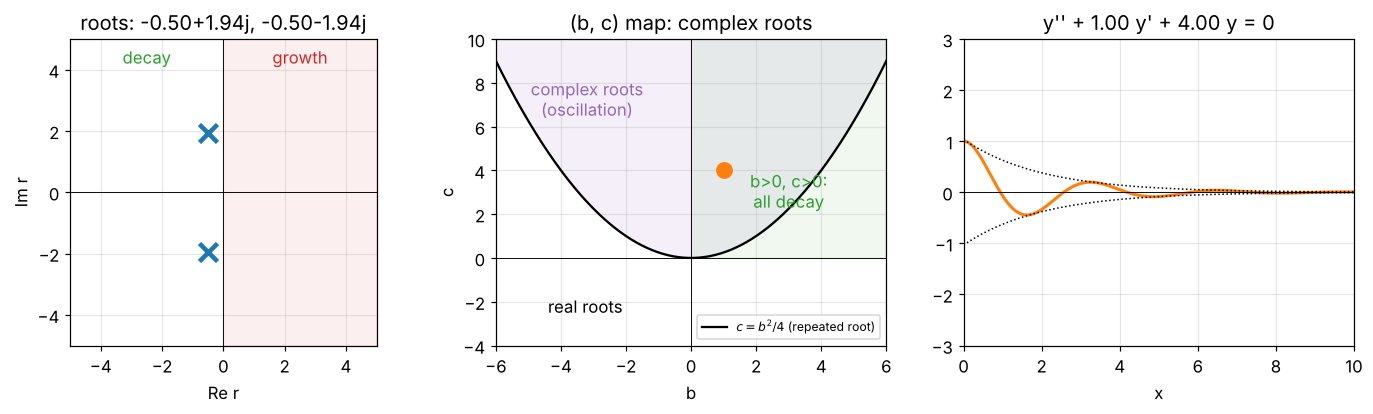

In [9]:
def plot_roots(b=1.0, c=4.0):
    """Roots of r^2 + b r + c, position in the (b, c) map, and the solution y(0)=1, y'(0)=0."""
    r1, r2 = ol.characteristic_roots(1, b, c)
    disc = b * b - 4 * c
    if abs(disc) <= 1e-12:
        case = "repeated root"
    else:
        case = "distinct real roots" if disc > 0 else "complex roots"

    fig, axs = plt.subplots(1, 3, figsize=(13, 3.9))
    # (1) complex plane: crosses at the roots, shaded right half-plane = growth
    ax = axs[0]
    ax.axvspan(0, 5, color="tab:red", alpha=0.07)
    ax.plot([r1.real, r2.real], [r1.imag, r2.imag], "x", ms=12, mew=3, color="tab:blue")
    ax.axhline(0, color="k", lw=0.6)
    ax.axvline(0, color="k", lw=0.6)
    ax.set(xlim=(-5, 5), ylim=(-5, 5), aspect="equal", xlabel="Re r", ylabel="Im r",
           title=f"roots: {r1:.2f}, {r2:.2f}".replace("+0.00j", "").replace("-0.00j", ""))
    ax.text(2.5, 4.2, "growth", ha="center", color="tab:red")
    ax.text(-2.5, 4.2, "decay", ha="center", color="tab:green")
    # (2) (b, c) map with the discriminant parabola
    ax = axs[1]
    bb = np.linspace(-6, 6, 300)
    ax.plot(bb, bb**2 / 4, "k", lw=1.5, label=r"$c = b^2/4$ (repeated root)")
    ax.fill_between(bb, bb**2 / 4, 10, color="tab:purple", alpha=0.1)
    ax.text(-3.2, 6.5, "complex roots\n(oscillation)", ha="center", color="tab:purple")
    ax.text(-4.4, -2.5, "real roots", color="k")
    ax.fill_between([0, 6], [0, 0], [10, 10], color="tab:green", alpha=0.07)
    ax.text(3.0, 2.3, "b>0, c>0:\nall decay", color="tab:green", ha="center")
    ax.plot(b, c, "o", ms=10, color="tab:orange")
    ax.axhline(0, color="k", lw=0.6)
    ax.axvline(0, color="k", lw=0.6)
    ax.set(xlim=(-6, 6), ylim=(-4, 10), xlabel="b", ylabel="c", title=f"(b, c) map: {case}")
    ax.legend(loc="lower right", fontsize=8)
    # (3) the solution
    ax = axs[2]
    xs = np.linspace(0, 10, 600)
    ys = ol.constant_coefficient_solution(xs, 1, b, c, 1.0, 0.0)
    ax.plot(xs, np.clip(ys, -3, 3), lw=2, color="tab:orange")
    if disc < -1e-12:                                   # envelope +- R e^{alpha x}
        al, be = r1.real, r1.imag
        R = np.hypot(1.0, -al / be)                     # amplitude of cos + ((0 - al*1)/be) sin
        for s in (1, -1):
            ax.plot(xs, np.clip(s * R * np.exp(al * xs), -3, 3), "k:", lw=1)
    ax.axhline(0, color="k", lw=0.6)
    ax.set(xlim=(0, 10), ylim=(-3, 3), xlabel="x", title=f"y'' + {b:.2f} y' + {c:.2f} y = 0")
    plt.tight_layout()
    plt.show()


plot_roots(1.0, 4.0)

In [10]:
interact(plot_roots,
         b=FloatSlider(value=1.0, min=-2.0, max=6.0, step=0.1, description="b", continuous_update=False),
         c=FloatSlider(value=4.0, min=-3.0, max=9.0, step=0.1, description="c", continuous_update=False));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='b', max=6.0, min=-2.0), Flo…

Things to try: $b = 0$ (pure oscillation, roots on the imaginary axis); $b = 4, c = 4$ (on the parabola:
repeated root $-2$); $b = 5, c = 4$ (roots $-1, -4$, no oscillation); $c < 0$ (a positive real root:
growth); $b < 0 < c$ (growing oscillations).

## 8. Higher order: the same song and dance

For $a_ny^{(n)} + \dots + a_1y' + a_0y = 0$ the identity of Section 1 still holds, so $e^{rx}$ is a solution
exactly when $r$ is a root of the degree-$n$ characteristic polynomial. A root of multiplicity
$m$ contributes $e^{rx}, xe^{rx}, \dots, x^{m-1}e^{rx}$ (the factorisation argument of Section 2,
repeated $m$ times) [L, Section 2.3].

**[L, Example 2.3.3]:** $y''' - 3y'' - y' + 3y = 0$: $\;r^3 - 3r^2 - r + 3 = (r - 3)(r - 1)(r + 1)$, so
$y = C_1e^{3x} + C_2e^{x} + C_3e^{-x}$. (Notebook 05 computed its Wronskian, $-16e^{3x}$.)

In [11]:
P3 = r**3 - 3 * r**2 - r + 3
print("factorisation:", sp.factor(P3))
ode3 = sp.Eq(y(x).diff(x, 3) - 3 * y(x).diff(x, 2) - y(x).diff(x) + 3 * y(x), 0)
display(sp.dsolve(ode3, y(x)))

# A repeated root of multiplicity 3: (D + 1)^3 y = 0
ode4 = sp.Eq(y(x).diff(x, 3) + 3 * y(x).diff(x, 2) + 3 * y(x).diff(x) + y(x), 0)
display(sp.dsolve(ode4, y(x)))

factorisation: (r - 3)*(r - 1)*(r + 1)


Eq(y(x), C1*exp(-x) + C2*exp(x) + C3*exp(3*x))

Eq(y(x), (C1 + x*(C2 + C3*x))*exp(-x))

## 9. Summary, exercises and references

| $b^2 - 4ac$ | roots | general solution | Wronskian of the basis |
|---|---|---|---|
| $> 0$ | $r_1 \neq r_2$ real | $C_1e^{r_1x} + C_2e^{r_2x}$ | $(r_2 - r_1)\,e^{(r_1+r_2)x}$ |
| $= 0$ | $r$ double | $(C_1 + C_2x)\,e^{rx}$ | $e^{2rx}$ |
| $< 0$ | $\alpha \pm i\beta$ | $e^{\alpha x}(C_1\cos\beta x + C_2\sin\beta x)$ | $\beta\,e^{2\alpha x}$ |

In every case $W \propto e^{(r_1+r_2)x} = e^{-bx/a}$, as Abel's theorem requires.

### Exercises

1. *(AD 3.3, Exercises 1-12, selection)* General solution of: (a) $y'' - y' - 2y = 0$;
   (b) $y'' + 8y' + 16y = 0$; (c) $y'' + 2y' + 5y = 0$; (d) $2y'' - 12y' + 18y = 0$.
   Check each answer with `sp.dsolve`.
2. *(AD 3.3, Exercises 14 and 16)* Solve $y'' - 3y' - 10y = 0$, $y(0) = 5$, $y'(0) = 4$, and
   $y'' + 4y' + 13y = 0$, $y(0) = 1$, $y'(0) = 5$. Check with `ol.constant_coefficient_solution`.
3. *(AD 3.3, Exercise 18)* Find $q(s) = s^2 + bs + c$ whose solutions are $e^{r_1t}, e^{r_2t}$;
   compute the Wronskian and the constant $K$ in Abel's formula $W = Ke^{-bt}$.
4. Using the factorisation of Section 2, solve $y'' - 2ry' + r^2y = 0$ step by step, and show that
   *every* solution is $(C_1 + C_2x)e^{rx}$.
5. Prove that if $b^2 < 4ac$ a nonzero solution has infinitely many zeros, spaced exactly
   $\pi/\beta$ apart. Compare with the Sturm separation theorem of notebook 05.
6. For which real $k$ do all solutions of $y'' + ky' + 4y = 0$ tend to zero? Oscillate? Use the slider
   of Section 7 to check.
7. *(L, Section 2.3)* Find the general solution of $y''' - y = 0$. (Hint: one real root and a
   complex pair.)

### References

* **[L]** J. Lebl, *Notes on Diffy Qs: Differential Equations for Engineers*,
  `ode/FullText_Diff_Eq_For_Engineers.pdf`, Sections 2.2 and 2.3. (Course textbook.)
* **[AD]** W.A. Adkins, M.G. Davidson, *Ordinary Differential Equations*, Springer UTM (2012),
  Section 3.3.
* **[AWH]** G.B. Arfken, H.J. Weber, F.E. Harris, *Mathematical Methods for Physicists*,
  7th ed., Academic Press (2013), Section 7.6.
* Notebook 05 of this series (Wronskian, Vandermonde determinant, Abel's theorem).